# Age Group Prediction with KNN (UTKFace)
Nebras Jafail

Goal: predict the age group of a face image with KNN and use it in a Streamlit app with webcam.

Age groups:
- child (0-12)
- teen (13-19)
- young adult (20-35)
- adult (36-59)
- senior (60+)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from keras.utils import load_img, img_to_array
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## 1. Look at the data
All images are in one folder. The age is the first number in the file name, for example `25_0_1_2017....jpg` means age 25.

In [2]:
data_dir = r'C:\Users\Nebras-PC\Downloads\archive (6)\UTKFace'

files = os.listdir(data_dir)
print("Number of images:", len(files))
files[:5]

Number of images: 23708


['100_0_0_20170112213500903.jpg.chip.jpg',
 '100_0_0_20170112215240346.jpg.chip.jpg',
 '100_1_0_20170110183726390.jpg.chip.jpg',
 '100_1_0_20170112213001988.jpg.chip.jpg',
 '100_1_0_20170112213303693.jpg.chip.jpg']

In [3]:
# get the age from the file name
ages = [int(f.split('_')[0]) for f in files]

df = pd.DataFrame({'file': files, 'age': ages})
df['age'].describe()

count    23708.000000
mean        33.303484
std         19.886112
min          1.000000
25%         23.000000
50%         29.000000
75%         45.000000
max        116.000000
Name: age, dtype: float64

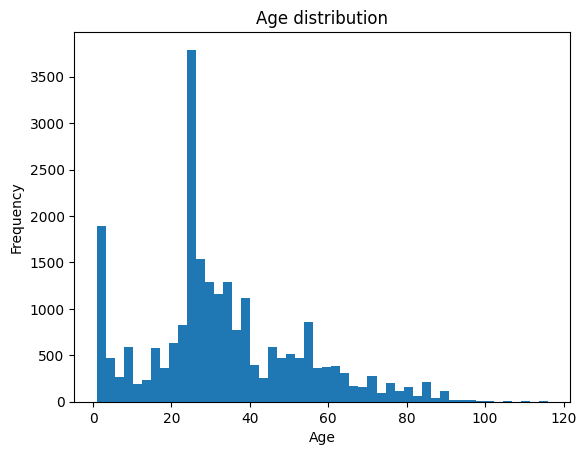

In [4]:
df['age'].plot(kind='hist', bins=50, title='Age distribution')
plt.xlabel('Age')
plt.show()

In [5]:
# turn age into age groups
class_names = ['child', 'teen', 'young adult', 'adult', 'senior']

df['group'] = pd.cut(df['age'], bins=[0, 12, 19, 35, 59, 120], labels=[0, 1, 2, 3, 4]).astype(int)
df['group'].map(dict(enumerate(class_names))).value_counts()

group
young adult    10514
adult           5911
child           3413
senior          2690
teen            1180
Name: count, dtype: int64

The groups are not balanced: young adult has the most images.

## 2. Load and prepare the images
KNN is slow with many features, so I use small images: 32x32 gray = 1024 pixels per image.

In [6]:
IMG_SIZE = 32

X = []
for f in df['file']:
    img = load_img(os.path.join(data_dir, f), color_mode='grayscale', target_size=(IMG_SIZE, IMG_SIZE))
    X.append(img_to_array(img))

X = np.array(X, dtype='float32')
y = df['group'].values

print(X.shape, y.shape)

(23708, 32, 32, 1) (23708,)


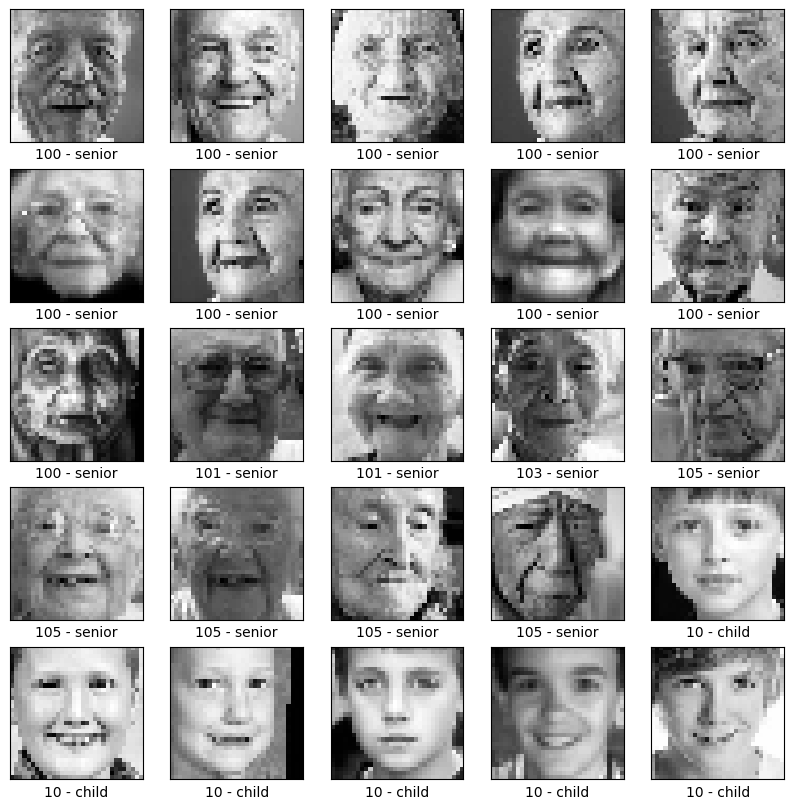

In [7]:
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X[i], cmap="gray")
    plt.xticks([])
    plt.yticks([])
    plt.xlabel(f"{df['age'][i]} - {class_names[y[i]]}")
plt.show()

In [8]:
# scale pixels to be between 0 and 1
X = X / 255

# KNN needs a table: each image becomes one row of 1024 pixels
X = X.reshape(len(X), -1)
X.shape

(23708, 1024)

In [9]:
# test data is kept for the end only
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)

(18966, 1024) (4742, 1024)


## 3. Model 1: KNN (baseline, k=5)

In [10]:
# Step1: Define the model
knn = KNeighborsClassifier(n_neighbors=5)

# Step2: Fit (fast)
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](5,)","[0,1,2,3,4]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [11]:
# Step3: Predict (slow, KNN compares every test image with all train images)
y_pred = knn.predict(X_test)

print(f"Test Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print(classification_report(y_test, y_pred, target_names=class_names))

Test Accuracy: 52.51%
              precision    recall  f1-score   support

       child       0.62      0.68      0.65       683
        teen       0.12      0.05      0.07       236
 young adult       0.59      0.71      0.64      2103
       adult       0.39      0.36      0.37      1182
      senior       0.41      0.19      0.26       538

    accuracy                           0.53      4742
   macro avg       0.42      0.40      0.40      4742
weighted avg       0.50      0.53      0.50      4742



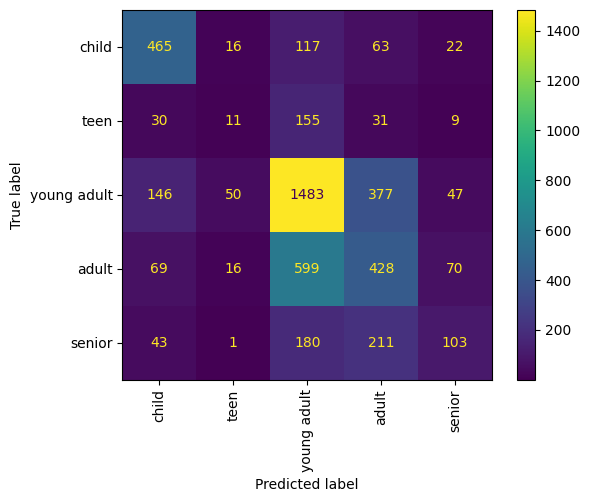

In [12]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=class_names, xticks_rotation='vertical')
plt.show()

## 4. Model 2: KNN with GridSearchCV (improvement)
Try different values of `n_neighbors` and `weights` to find the best ones (notebook 06).

In [13]:
param_grid = {'n_neighbors': [3, 5, 7, 9, 11],
              'weights': ['uniform', 'distance']}

grid_model = GridSearchCV(KNeighborsClassifier(), param_grid, cv=3)
grid_model.fit(X_train, y_train)

grid_model.best_params_

{'n_neighbors': 11, 'weights': 'distance'}

In [14]:
# see the score of every combination
pd.DataFrame(grid_model.cv_results_)[['params', 'mean_test_score']].sort_values('mean_test_score', ascending=False)

,params,mean_test_score
9,"{'n_neighbors': 11, 'weights': 'distance'}",0.541337
7,"{'n_neighbors': 9, 'weights': 'distance'}",0.536592
8,"{'n_neighbors': 11, 'weights': 'uniform'}",0.533165
5,"{'n_neighbors': 7, 'weights': 'distance'}",0.530159
6,"{'n_neighbors': 9, 'weights': 'uniform'}",0.527470
3,"{'n_neighbors': 5, 'weights': 'distance'}",0.525888
4,"{'n_neighbors': 7, 'weights': 'uniform'}",0.520405
2,"{'n_neighbors': 5, 'weights': 'uniform'}",0.517452
1,"{'n_neighbors': 3, 'weights': 'distance'}",0.501107
0,"{'n_neighbors': 3, 'weights': 'uniform'}",0.477855


Best KNN Test Accuracy: 56.07%
              precision    recall  f1-score   support

       child       0.72      0.64      0.68       683
        teen       0.33      0.04      0.07       236
 young adult       0.62      0.73      0.67      2103
       adult       0.40      0.45      0.42      1182
      senior       0.47      0.26      0.34       538

    accuracy                           0.56      4742
   macro avg       0.51      0.42      0.44      4742
weighted avg       0.55      0.56      0.54      4742



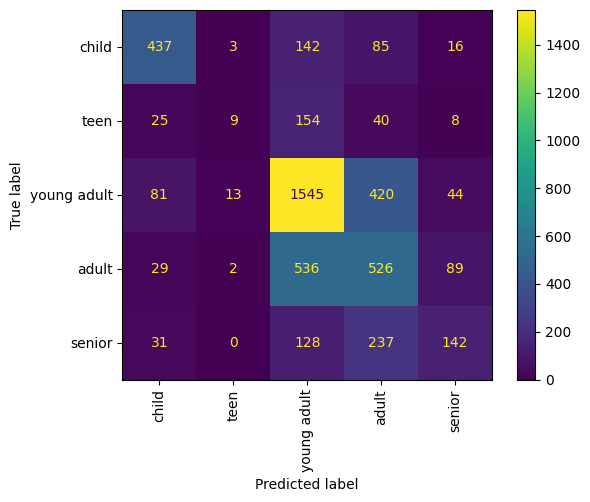

In [15]:
best_knn = grid_model.best_estimator_

y_pred_best = best_knn.predict(X_test)

print(f"Best KNN Test Accuracy: {accuracy_score(y_test, y_pred_best) * 100:.2f}%")
print(classification_report(y_test, y_pred_best, target_names=class_names))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best, display_labels=class_names, xticks_rotation='vertical')
plt.show()

## 5. Images the model got wrong

Wrong predictions: 2083


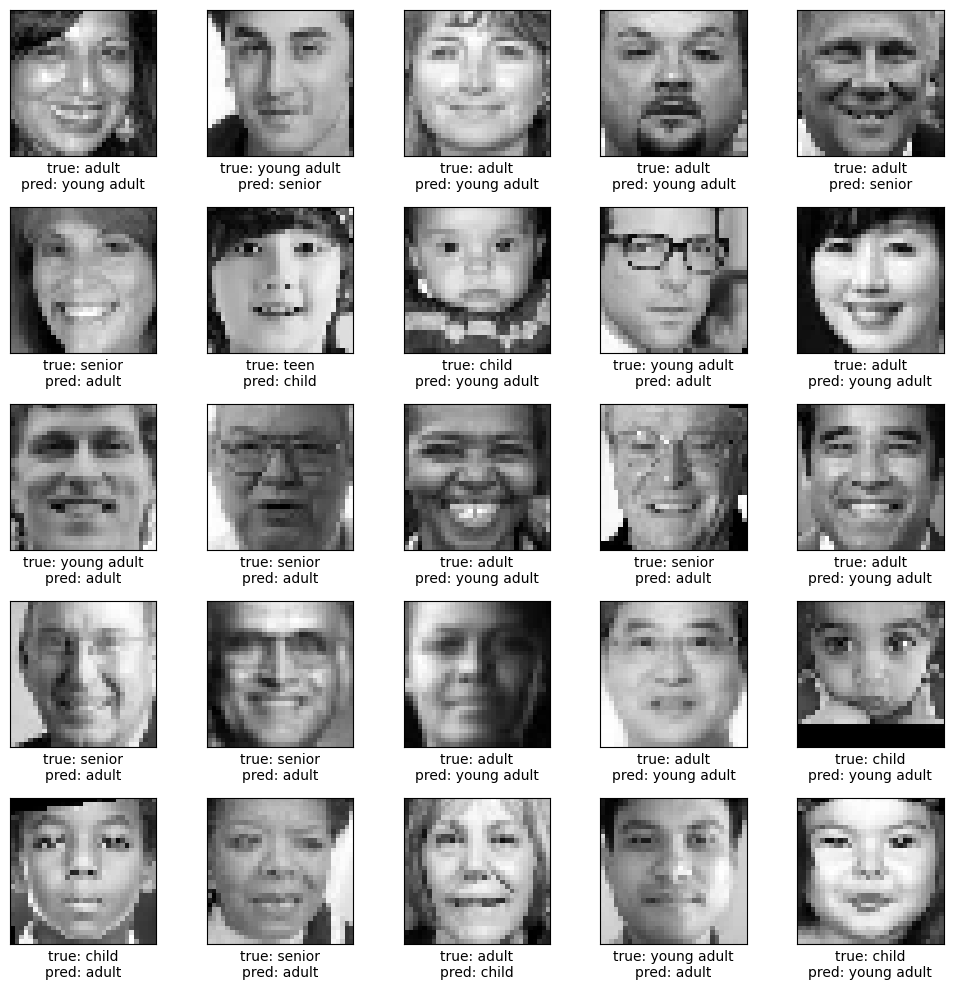

In [16]:
idx = np.where(y_test != y_pred_best)[0]
print("Wrong predictions:", len(idx))

plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_test[idx[i]].reshape(IMG_SIZE, IMG_SIZE), cmap="gray")
    plt.xticks([])
    plt.yticks([])
    plt.xlabel(f"true: {class_names[y_test[idx[i]]]}\npred: {class_names[y_pred_best[idx[i]]]}")
plt.tight_layout()
plt.show()

What I noticed (update after running):
- Most mistakes are between neighbour groups, for example teen and young adult, or adult and senior.
- People near the border age (like 19 or 36) are hard to put in one group.
- KNN only compares pixels, so lighting and face position matter a lot.

## 6. Save the model

In [17]:
# compress=3 makes the file smaller (KNN keeps all training images inside)
joblib.dump(best_knn, "age_knn.pkl", compress=3)
print("Model saved!")

Model saved!


## 7. Limitations
- KNN compares raw pixels, it does not understand face features like wrinkles.
- Age groups have hard borders, but real faces do not change suddenly at 20 or 60.
- Some groups have fewer images, so they are weaker.
- The dataset may not represent all races and ages equally.